In [2]:
!pip install pandas numpy matplotlib seaborn scikit-learn plotly folium streamlit streamlit-folium joblib

     -------------------------------------- 524.6/524.6 kB 2.7 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import folium
from folium.plugins import HeatMap, MarkerCluster

import warnings
import time
import joblib
import os

warnings.filterwarnings("ignore")

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


# load dataset

In [4]:
file_path = "Crime_Data_from_2020_to_Present.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1005198, 28)


In [5]:
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,3/1/2020 0:00,3/1/2020 0:00,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,2/9/2020 0:00,2/8/2020 0:00,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11/11/2020 0:00,11/4/2020 0:00,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,5/10/2023 0:00,3/10/2020 0:00,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,200412582,9/9/2020 0:00,9/9/2020 0:00,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,200 E AVENUE 28,NaN,34.0820,-118.2130


In [6]:
df.tail()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
1005193,250304214,2/23/2025 0:00,2/21/2025 0:00,1530,3,Southwest,358,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,3600 MCCLINTOCK AV,NaN,34.0212,-118.2895
1005194,250304203,2/20/2025 0:00,2/13/2025 0:00,2100,3,Southwest,325,1,522,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",...,IC,Invest Cont,522.0,NaN,NaN,NaN,2600 ELLENDALE PL,NaN,34.0307,-118.2923
1005195,250504051,1/14/2025 0:00,1/14/2025 0:00,1250,5,Harbor,509,1,210,ROBBERY,...,IC,Invest Cont,210.0,NaN,NaN,NaN,24300 WESTERN AV,NaN,33.8046,-118.3074
1005196,251604136,2/27/2025 0:00,2/27/2025 0:00,1550,16,Foothill,1664,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,NaN,NaN,NaN,11900 SHELDON ST,NaN,34.2404,-118.3922
1005197,251904210,3/25/2025 0:00,3/25/2025 0:00,1235,19,Mission,1944,2,850,INDECENT EXPOSURE,...,IC,Invest Cont,850.0,NaN,NaN,NaN,11100 OMELVENY AV,NaN,34.2722,-118.4417


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1005198
Columns: 28


# inspect dataset 

In [8]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT', 'LON']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005198 entries, 0 to 1005197
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1005198 non-null  int64  
 1   Date Rptd       1005198 non-null  object 
 2   DATE OCC        1005198 non-null  object 
 3   TIME OCC        1005198 non-null  int64  
 4   AREA            1005198 non-null  int64  
 5   AREA NAME       1005198 non-null  object 
 6   Rpt Dist No     1005198 non-null  int64  
 7   Part 1-2        1005198 non-null  int64  
 8   Crm Cd          1005198 non-null  int64  
 9   Crm Cd Desc     1005198 non-null  object 
 10  Mocodes         853438 non-null   object 
 11  Vict Age        1005198 non-null  int64  
 12  Vict Sex        860416 non-null   object 
 13  Vict Descent    860404 non-null   object 
 14  Premis Cd       1005182 non-null  float64
 15  Premis Desc     1004610 non-null  object 
 16  Weapon Used Cd  327280 non-null   fl

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DR_NO,1005198.0,NaN,NaN,NaN,220227677.865526,13202822.081133,817.0,210616927.25,220916044.0,231110516.25,252104146.0
Date Rptd,1005198,1906,2/2/2023 0:00,929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DATE OCC,1005198,1901,1/1/2020 0:00,1164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TIME OCC,1005198.0,NaN,NaN,NaN,1339.911378,651.053143,1.0,900.0,1420.0,1900.0,2359.0
AREA,1005198.0,NaN,NaN,NaN,10.690975,6.110385,1.0,5.0,11.0,16.0,21.0
AREA NAME,1005198,21,Central,69674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rpt Dist No,1005198.0,NaN,NaN,NaN,1115.556245,611.173335,101.0,587.0,1139.0,1613.0,2199.0
Part 1-2,1005198.0,NaN,NaN,NaN,1.400283,0.489956,1.0,1.0,1.0,2.0,2.0
Crm Cd,1005198.0,NaN,NaN,NaN,500.145783,205.263461,110.0,331.0,442.0,626.0,956.0
Crm Cd Desc,1005198,140,VEHICLE - STOLEN,115247,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# PART 4 — Missing Value Analysis

In [11]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
Crm Cd 4,1005134,99.993633
Crm Cd 3,1002884,99.769797
Crm Cd 2,936039,93.119863
Cross Street,850955,84.655461
Weapon Used Cd,677918,67.441240
Weapon Desc,677918,67.441240
Mocodes,151760,15.097523
Vict Descent,144794,14.404525
Vict Sex,144782,14.403331
Premis Desc,588,0.058496


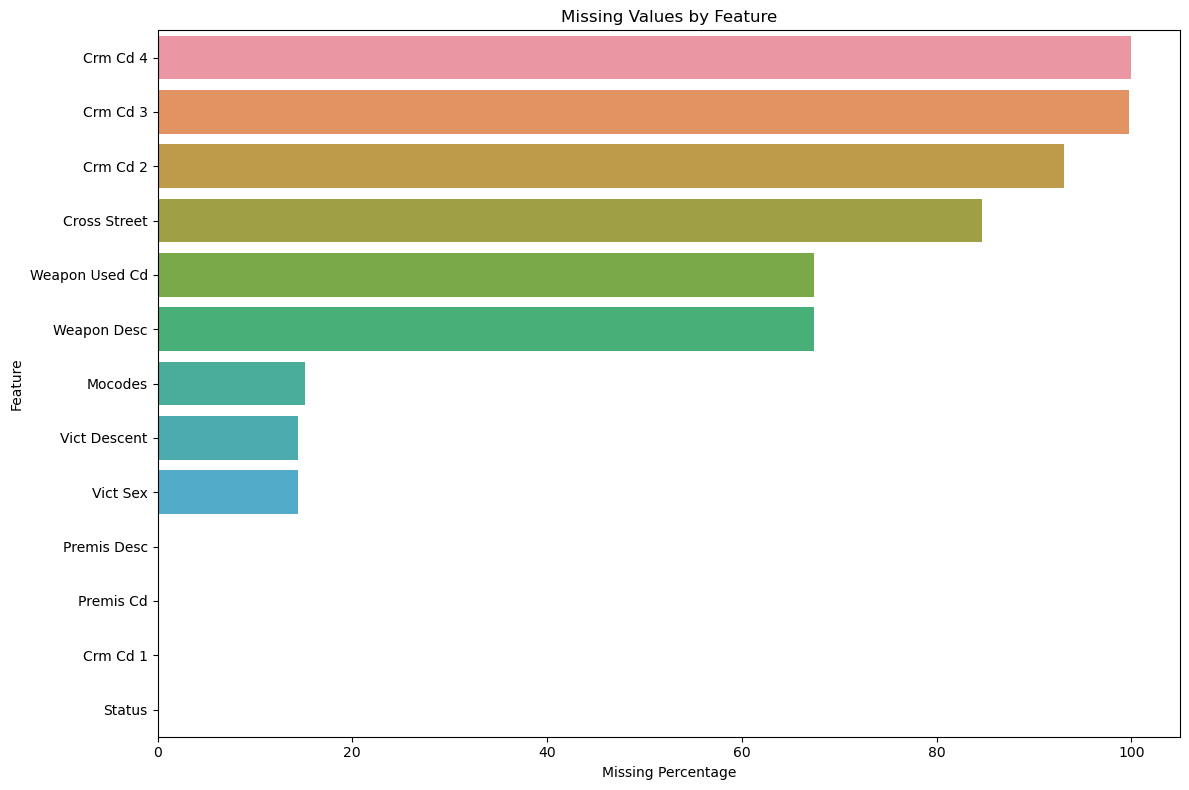

In [12]:
plt.figure(figsize=(12, 8))

missing_nonzero = missing[
    missing["Missing_Count"] > 0
]

sns.barplot(
    x=missing_nonzero["Missing_Percentage"],
    y=missing_nonzero.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# PART 5 — Duplicate Detection

In [13]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


# PART 6 — Date Processing

In [14]:
df["Date Rptd"] = pd.to_datetime(
    df["Date Rptd"],
    errors="coerce"
)

df["DATE OCC"] = pd.to_datetime(
    df["DATE OCC"],
    errors="coerce"
)

# PART 7 — Feature Engineering

In [15]:
df["Year"] = df["DATE OCC"].dt.year

In [16]:
df["Month"] = df["DATE OCC"].dt.month

In [17]:
df["Day"] = df["DATE OCC"].dt.day

In [19]:
df["DayOfWeek"] = df["DATE OCC"].dt.dayofweek

In [20]:
df["DayName"] = df["DATE OCC"].dt.day_name()

# PART 8 — Process TIME OCC

In [22]:
df["TIME OCC"] = pd.to_numeric(
    df["TIME OCC"],
    errors="coerce"
)

df["Hour"] = (df["TIME OCC"] // 100)

df["Hour"] = pd.to_numeric(
    df["Hour"],
    errors="coerce"
)

df.loc[
    ~df["Hour"].between(0, 23),
    "Hour"
] = np.nan

df["Hour"].value_counts().sort_index()

0.0     40481
1.0     29764
2.0     25217
3.0     22193
4.0     18758
5.0     17292
6.0     23187
7.0     26270
8.0     37257
9.0     36534
10.0    43029
11.0    43670
12.0    67836
13.0    45593
14.0    49324
15.0    52839
16.0    52987
17.0    58827
18.0    59966
19.0    55616
20.0    56358
21.0    50800
22.0    49117
23.0    42283
Name: Hour, dtype: int64

# PART 9 — Weekend Feature

In [46]:
df["IsWeekend"] = (
    df["DayOfWeek"] >= 5
).astype(int)

df["IsWeekend"].value_counts()

0    718062
1    287136
Name: IsWeekend, dtype: int64

# PART 10 — Time of Day

In [23]:
def get_time_of_day(hour):

    if pd.isna(hour):
        return "Unknown"

    elif 5 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"

In [24]:
df["TimeOfDay"] = df["Hour"].apply(
    get_time_of_day
)

In [25]:
df["TimeOfDay"].value_counts()

Night        278613
Afternoon    268579
Evening      230767
Morning      227239
Name: TimeOfDay, dtype: int64

# PART 11 — Season

In [26]:
def get_season(month):

    if pd.isna(month):
        return "Unknown"

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"

df["Season"] = df["Month"].apply(
    get_season
)

# PART 12 — Victim Age Cleaning

In [27]:
df["Vict Age"] = pd.to_numeric(
    df["Vict Age"],
    errors="coerce"
)
df.loc[
    (df["Vict Age"] <= 0) |
    (df["Vict Age"] > 100),
    "Vict Age"
] = np.nan

# PART 13 — Latitude and Longitude Cleaning

In [48]:
df["LAT"] = pd.to_numeric(
    df["LAT"],
    errors="coerce"
)

df["LON"] = pd.to_numeric(
    df["LON"],
    errors="coerce"
)

# PART 14 — Check the Dataset Again

In [28]:
print("Final dataset shape:", df.shape)

Final dataset shape: (1005198, 36)


In [29]:
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,LAT,LON,Year,Month,Day,DayOfWeek,DayName,Hour,TimeOfDay,Season
0,190326475,2020-03-01,2020-03-01,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,34.0375,-118.3506,2020,3,1,6,Sunday,21.0,Night,Spring
1,200106753,2020-02-09,2020-02-08,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,34.0444,-118.2628,2020,2,8,5,Saturday,18.0,Evening,Winter
2,200320258,2020-11-11,2020-11-04,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,34.0210,-118.3002,2020,11,4,2,Wednesday,17.0,Evening,Autumn
3,200907217,2023-05-10,2020-03-10,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,34.1576,-118.4387,2020,3,10,1,Tuesday,20.0,Evening,Spring
4,200412582,2020-09-09,2020-09-09,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,34.0820,-118.2130,2020,9,9,2,Wednesday,6.0,Morning,Autumn


# MODULE 1 — EDA

# PART 15 — Crime Class Distribution

In [30]:
df["Part 1-2"].value_counts()

1    602834
2    402364
Name: Part 1-2, dtype: int64

In [31]:
df["Part 1-2"].value_counts(
    normalize=True
) * 100

1    59.971667
2    40.028333
Name: Part 1-2, dtype: float64

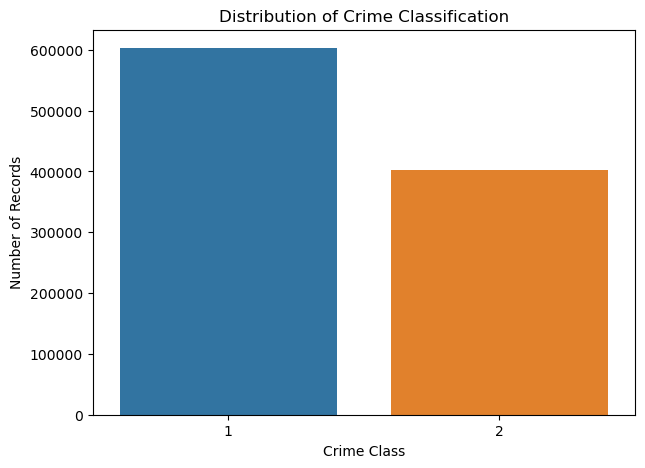

In [32]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Part 1-2"
)

plt.title("Distribution of Crime Classification")
plt.xlabel("Crime Class")
plt.ylabel("Number of Records")

plt.show()

# PART 16 — Crime Trend by Year

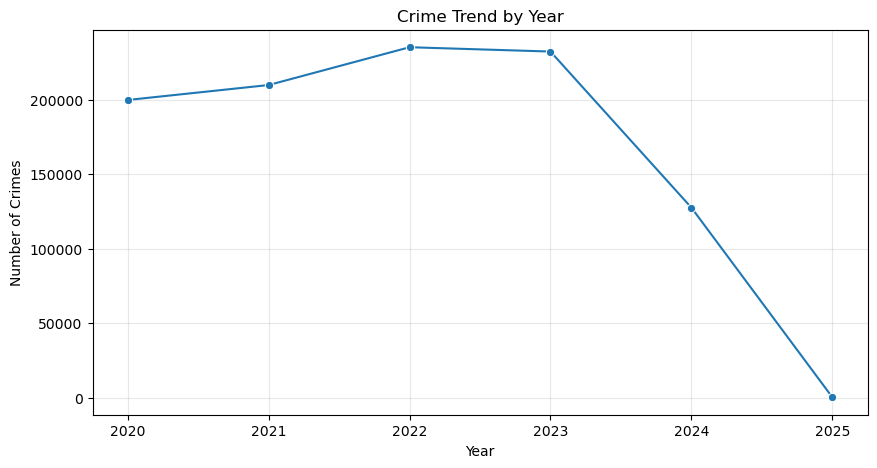

In [33]:
year_counts = (
    df["Year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker="o"
)

plt.title("Crime Trend by Year")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")

plt.grid(alpha=0.3)
plt.show()

# PART 17 — Crime by Month

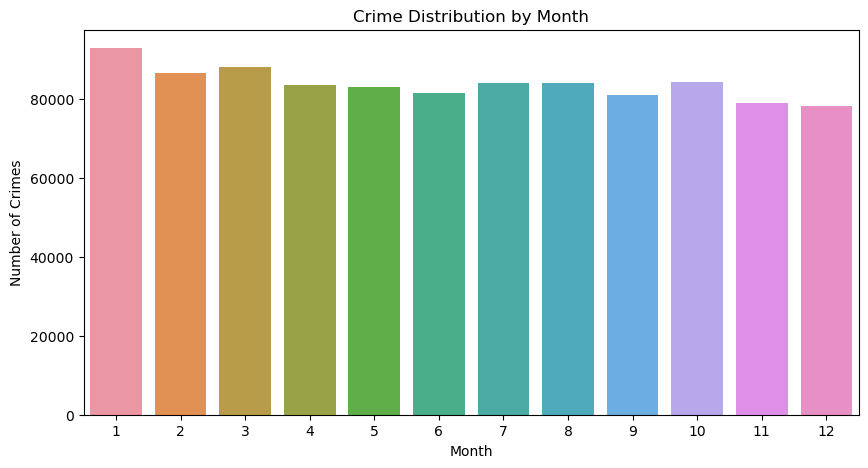

In [34]:
month_counts = (
    df["Month"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_counts.index,
    y=month_counts.values
)

plt.title("Crime Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")

plt.show()

# PART 18 — Crime by Hour

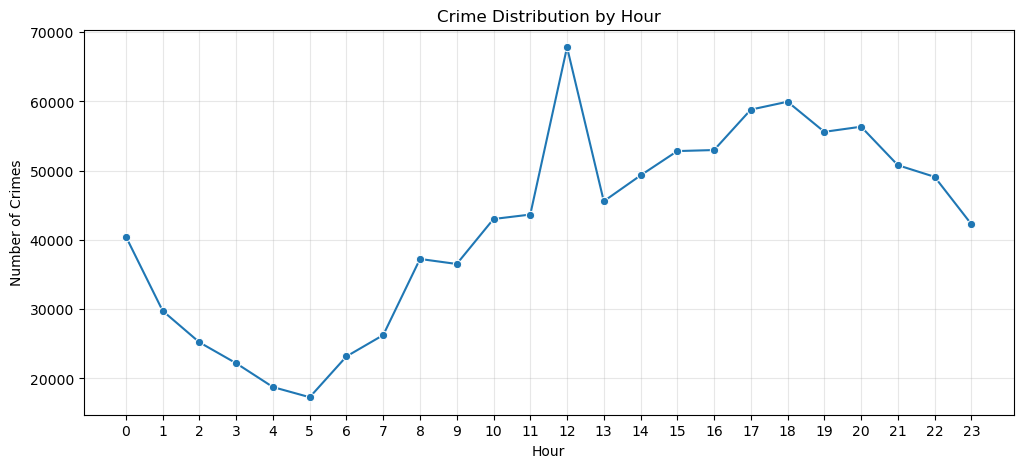

In [35]:
hour_counts = (
    df["Hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_counts.index,
    y=hour_counts.values,
    marker="o"
)

plt.xticks(range(24))

plt.title("Crime Distribution by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Crimes")

plt.grid(alpha=0.3)
plt.show()


# PART 19 — Crime by Day

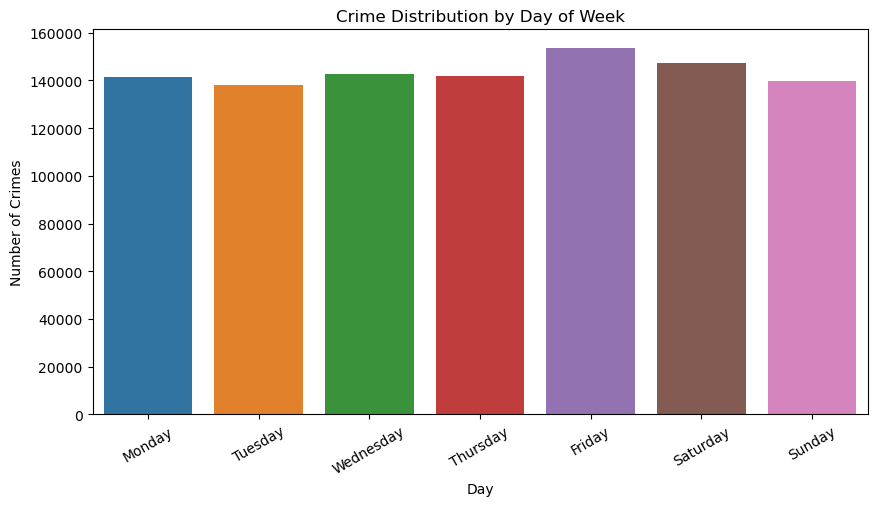

In [38]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="DayName",
    order=day_order
)

plt.title("Crime Distribution by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Crimes")

plt.xticks(rotation=30)

plt.show()

# PART 20 — Crime by Area

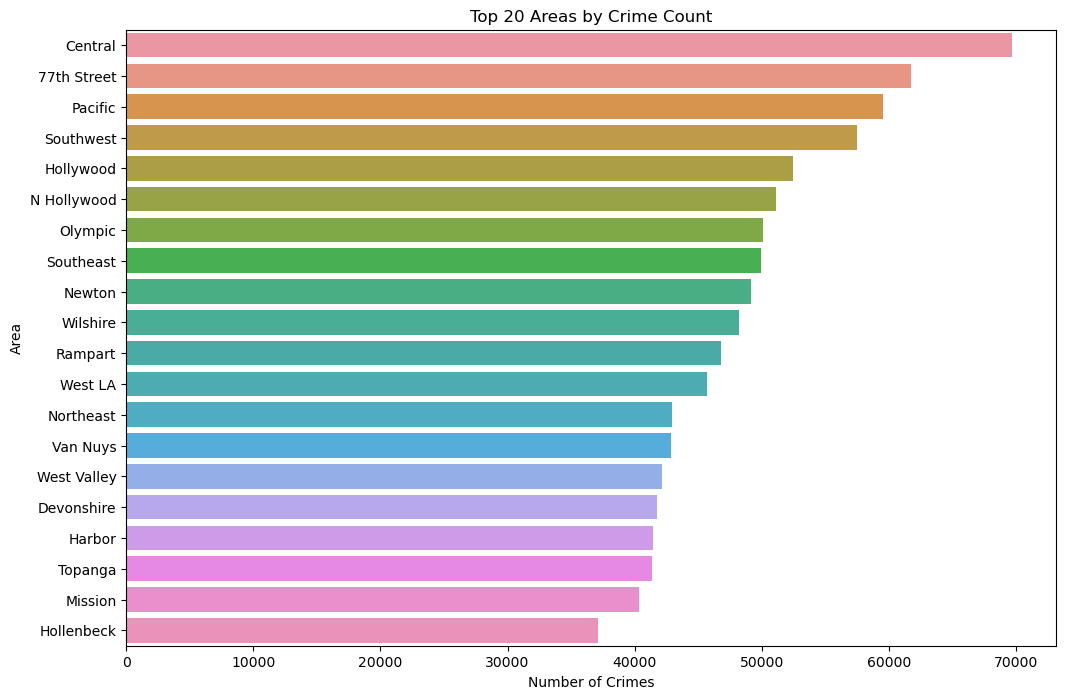

In [39]:
area_counts = (
    df["AREA NAME"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=area_counts.values,
    y=area_counts.index
)

plt.title("Top 20 Areas by Crime Count")
plt.xlabel("Number of Crimes")
plt.ylabel("Area")

plt.show()

# PART 21 — Top Crime Types

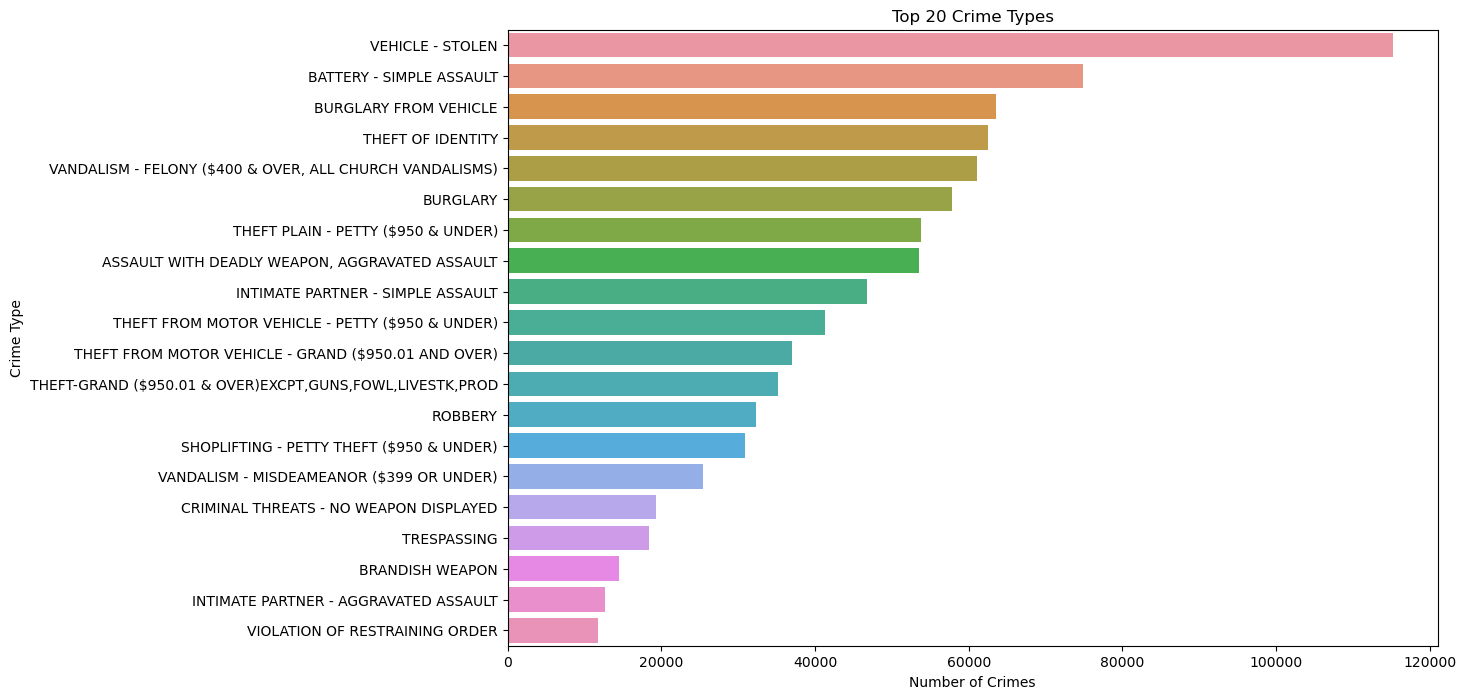

In [40]:
crime_counts = (
    df["Crm Cd Desc"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=crime_counts.values,
    y=crime_counts.index
)

plt.title("Top 20 Crime Types")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Type")

plt.show()

# PART 22 — Victim Age Distribution

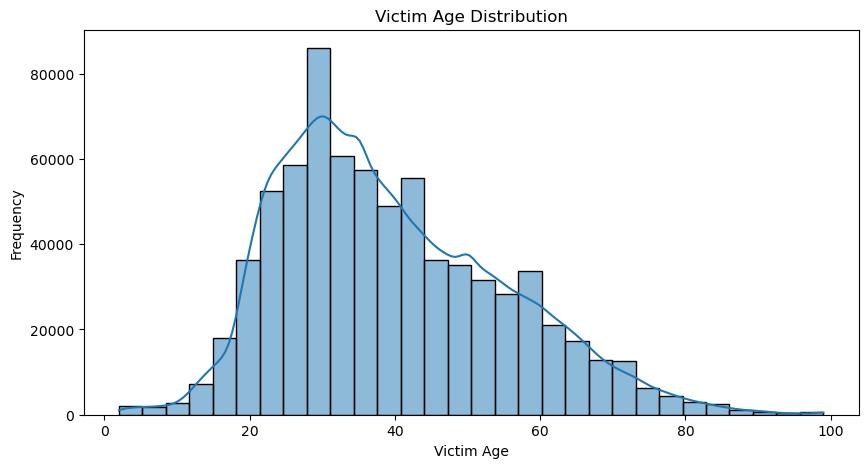

In [41]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Vict Age"].dropna(),
    bins=30,
    kde=True
)

plt.title("Victim Age Distribution")
plt.xlabel("Victim Age")
plt.ylabel("Frequency")

plt.show()

# PART 23 — Crime Class vs Time of Day

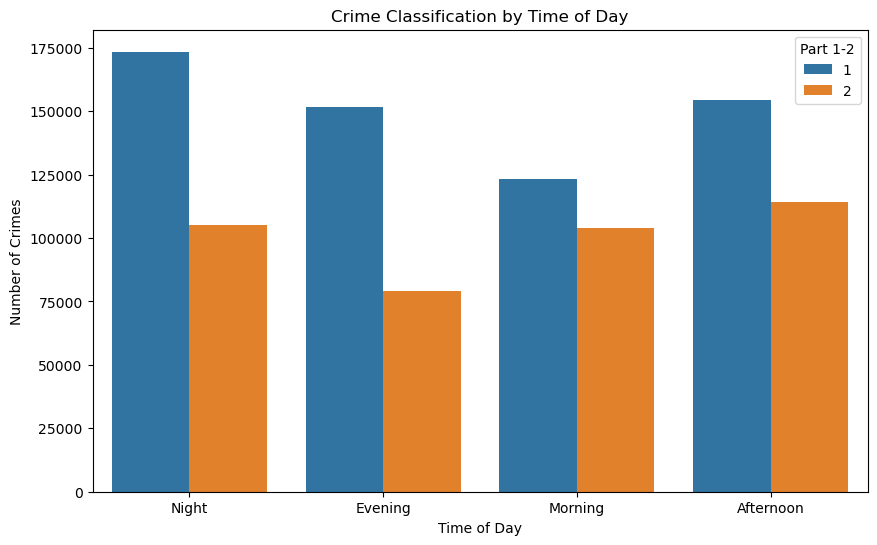

In [43]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="TimeOfDay",
    hue="Part 1-2"
)

plt.title("Crime Classification by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Crimes")

plt.show()

# PART 24 — Crime Class by Area

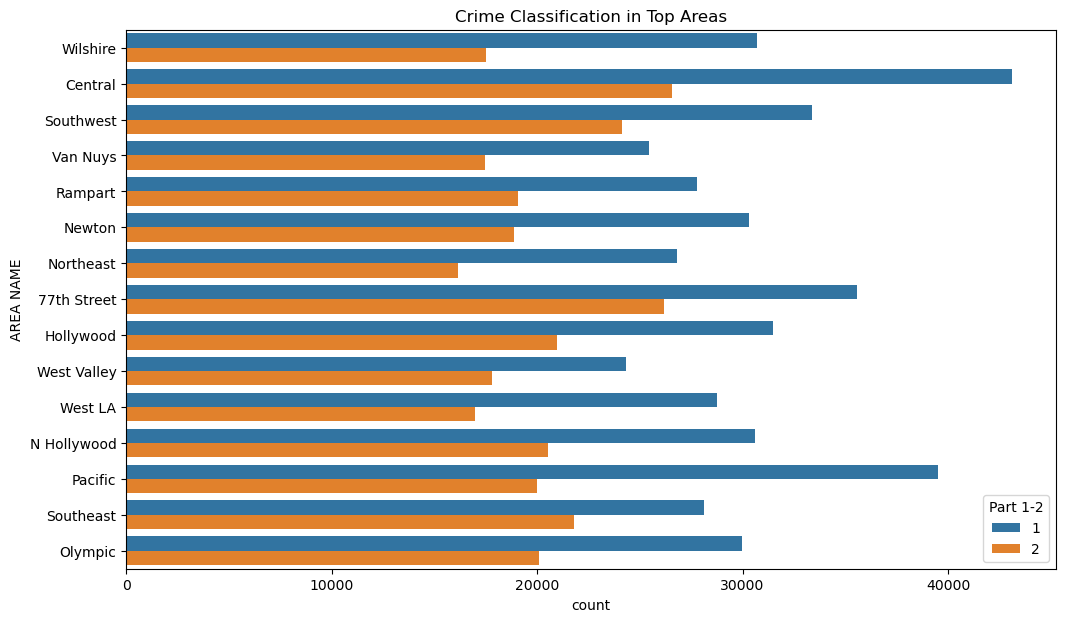

In [49]:
area_class = pd.crosstab(
    df["AREA NAME"],
    df["Part 1-2"]
)

area_class.head()

top_areas = (
    df["AREA NAME"]
    .value_counts()
    .head(15)
    .index
)

temp = df[
    df["AREA NAME"].isin(top_areas)
]

plt.figure(figsize=(12, 7))

sns.countplot(
    data=temp,
    y="AREA NAME",
    hue="Part 1-2"
)

plt.title("Crime Classification in Top Areas")

plt.show()


# MODULE 2 — CRIME CLASSIFICATION

# PART 25 — Select ML Features

In [44]:
features = [
    "AREA",
    "AREA NAME",
    "Vict Age",
    "Vict Sex",
    "Vict Descent",
    "Premis Desc",
    "Weapon Desc",
    "Hour",
    "Month",
    "DayOfWeek",
    "IsWeekend",
    "TimeOfDay",
    "Season"
]

target = "Part 1-2"

In [47]:
ml_df = df[
    features + [target]
].copy()

In [50]:
ml_df = ml_df.dropna(
    subset=[target]
)

# PART 26 — Convert Target to 0/1

In [51]:
ml_df[target] = (
    ml_df[target]
    .astype(int)
    .map({
        1: 0,
        2: 1
    })
)

In [52]:
print(
    ml_df[target].value_counts()
)

0    602834
1    402364
Name: Part 1-2, dtype: int64


# PART 27 — Sample Dataset for Classical ML

In [64]:
MODEL_SAMPLE_SIZE = 300000

if len(ml_df) > MODEL_SAMPLE_SIZE:

    model_df, _ = train_test_split(
        ml_df,
        train_size=MODEL_SAMPLE_SIZE,
        stratify=ml_df[target],
        random_state=42
    )

else:

    model_df = ml_df.copy()

print(
   "Dataset used for ML:",
    model_df.shape
)

Dataset used for ML: (300000, 14)


In [ ]:
PART 28 — X and y

In [54]:
X = model_df[features]

y = model_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (300000, 13)
y shape: (300000,)


# PART 29 — Train/Test Split

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [56]:
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (240000, 13)
Testing: (60000, 13)


# PART 30 — Numerical Features

In [57]:
numeric_features = [
    "AREA",
    "Vict Age",
    "Hour",
    "Month",
    "DayOfWeek",
    "IsWeekend"
]

# PART 31 — Categorical Features

In [58]:
categorical_features = [
    "AREA NAME",
    "Vict Sex",
    "Vict Descent",
    "Premis Desc",
    "Weapon Desc",
    "TimeOfDay",
    "Season"
]

# PART 32 — Preprocessing Pipeline

In [59]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

In [60]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [61]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

# PART 33 — Define ML Models

# logisctic regression

In [65]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

# support vector machine

In [66]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

# decision tree

In [67]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

# random forest

In [68]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

# 12. Create model dictionary

In [69]:
models = {

    "Logistic Regression":
        logistic_model,

    "SVM":
        svm_model,

    "Decision Tree":
        decision_tree_model,

    "Random Forest":
        random_forest_model
}

# Part 34. Train all four models

In [70]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import time

results = {}

trained_models = {}

predictions = {}

scores = {}

In [71]:
for name, model in models.items():

    print("=" * 70)
    print("Training:", name)

    # Create pipeline
    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )
        ]
    )

    # Start timer
    start_time = time.time()

    # Train
    pipeline.fit(
        X_train,
        y_train
    )

    # Training time
    training_time = (
        time.time() - start_time
    )

    # Prediction
    y_pred = pipeline.predict(
        X_test
    )

    # ------------------------------------------------
    # Probability / decision score
    # ------------------------------------------------

    if hasattr(
        pipeline.named_steps["model"],
        "predict_proba"
    ):

        y_score = (
            pipeline
            .predict_proba(
                X_test
            )[:, 1]
        )

    elif hasattr(
        pipeline.named_steps["model"],
        "decision_function"
    ):

        y_score = (
            pipeline
            .decision_function(
                X_test
            )
        )

    else:

        y_score = None

    # ------------------------------------------------
    # Metrics
    # ------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    if y_score is not None:

        roc_auc = roc_auc_score(
            y_test,
            y_score
        )

    else:

        roc_auc = np.nan

    # Store results
    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "Training Time (sec)": training_time
    }

    trained_models[name] = pipeline

    predictions[name] = y_pred

    scores[name] = y_score

    print(
        f"Accuracy  : {accuracy:.4f}"
    )

    print(
        f"Precision : {precision:.4f}"
    )

    print(
        f"Recall    : {recall:.4f}"
    )

    print(
        f"F1 Score  : {f1:.4f}"
    )

    print(
        f"ROC-AUC   : {roc_auc:.4f}"
    )

    print(
        f"Time      : {training_time:.2f} sec"
    )

Training: Logistic Regression
Accuracy  : 0.7412
Precision : 0.6584
Recall    : 0.7349
F1 Score  : 0.6945
ROC-AUC   : 0.8209
Time      : 3.76 sec
Training: SVM
Accuracy  : 0.7400
Precision : 0.6566
Recall    : 0.7349
F1 Score  : 0.6935
ROC-AUC   : 0.8200
Time      : 11.32 sec
Training: Decision Tree
Accuracy  : 0.7368
Precision : 0.6658
Recall    : 0.6878
F1 Score  : 0.6766
ROC-AUC   : 0.8160
Time      : 12.85 sec
Training: Random Forest
Accuracy  : 0.7507
Precision : 0.6556
Recall    : 0.7944
F1 Score  : 0.7184
ROC-AUC   : 0.8380
Time      : 44.60 sec


# PART 35 — Model Comparison

In [74]:
results_df = pd.DataFrame(
    results
).T.reset_index()

results_df = results_df.rename(
    columns={
        "index": "Model"
    }
)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(
    drop=True
)
results_df


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Random Forest,0.750700,0.655648,0.794437,0.718401,0.838016,44.599061
1,Logistic Regression,0.741233,0.658361,0.734896,0.694526,0.820949,3.761528
2,SVM,0.740017,0.656585,0.734854,0.693518,0.819979,11.323833
3,Decision Tree,0.736833,0.665793,0.687804,0.676620,0.815975,12.852271


# Accuracy comparison

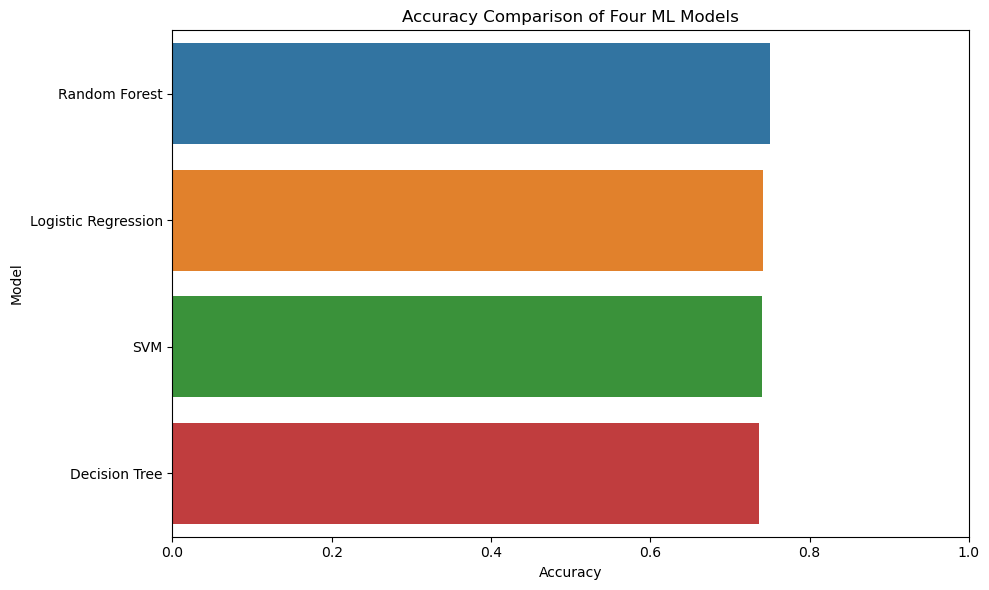

In [75]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.xlim(0, 1)

plt.title(
    "Accuracy Comparison of Four ML Models"
)

plt.xlabel("Accuracy")
plt.ylabel("Model")

plt.tight_layout()

plt.show()

# Precision comparison

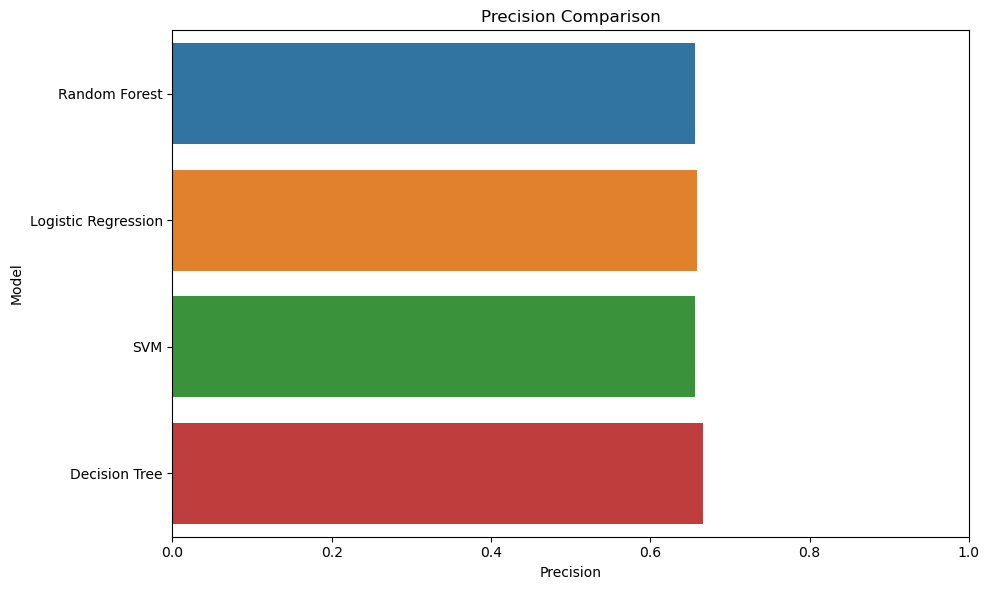

In [76]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Precision",
    y="Model"
)

plt.xlim(0, 1)

plt.title(
    "Precision Comparison"
)

plt.xlabel("Precision")
plt.ylabel("Model")

plt.tight_layout()

plt.show()

# Recall comparison

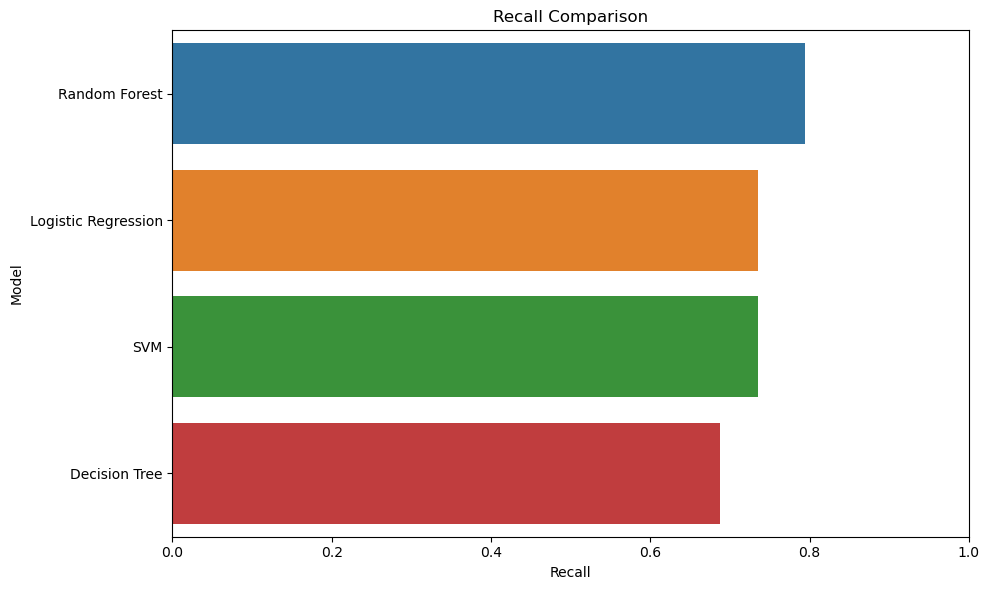

In [77]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Recall",
    y="Model"
)

plt.xlim(0, 1)

plt.title(
    "Recall Comparison"
)

plt.xlabel("Recall")
plt.ylabel("Model")

plt.tight_layout()

plt.show()

# Confusion Matrix for all four

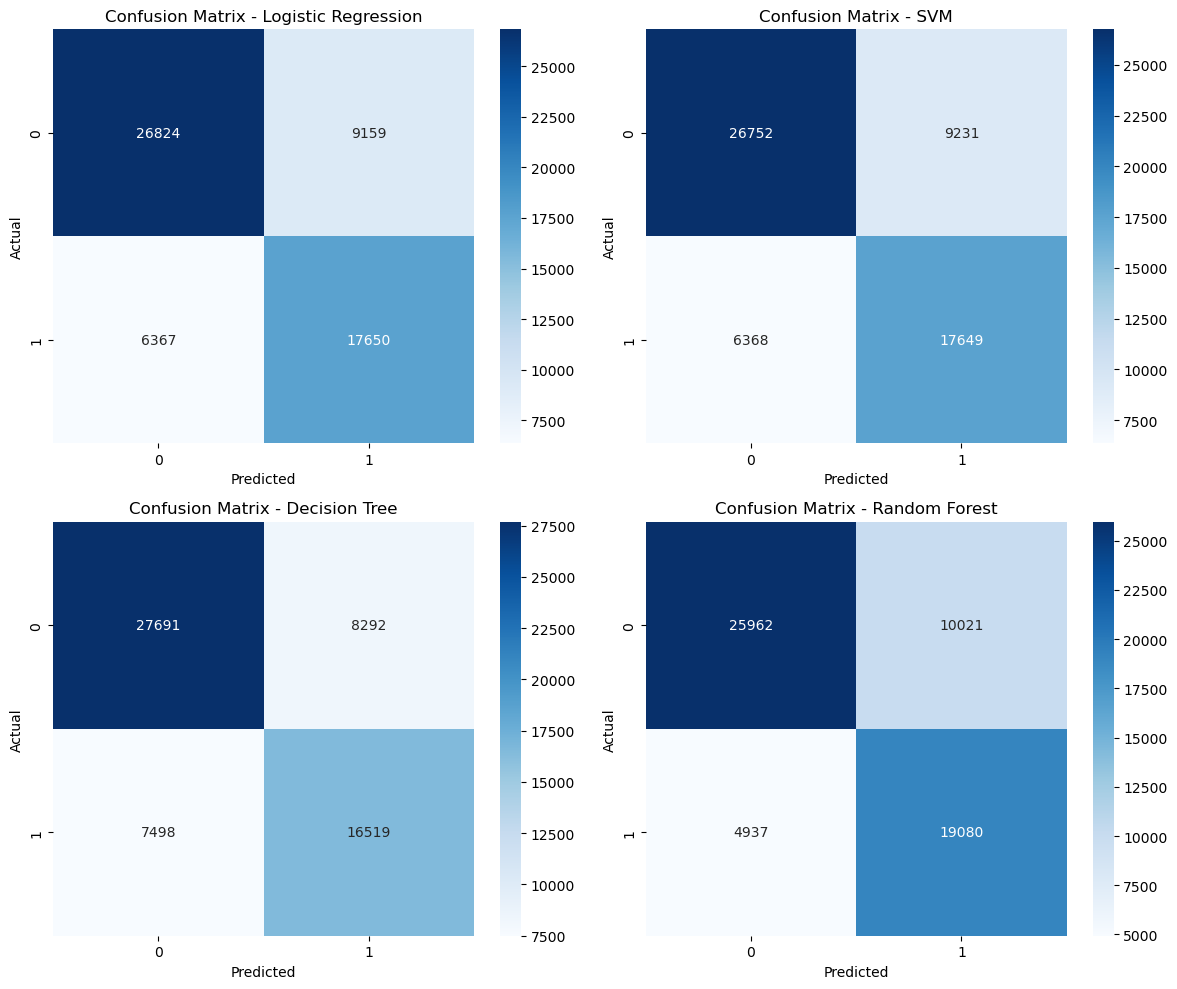

In [78]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 10)
)

axes = axes.flatten()

for i, name in enumerate(
    models.keys()
):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Confusion Matrix - {name}"
    )

    axes[i].set_xlabel(
        "Predicted"
    )

    axes[i].set_ylabel(
        "Actual"
    )

plt.tight_layout()

plt.show()

# 21. ROC Curves for all four

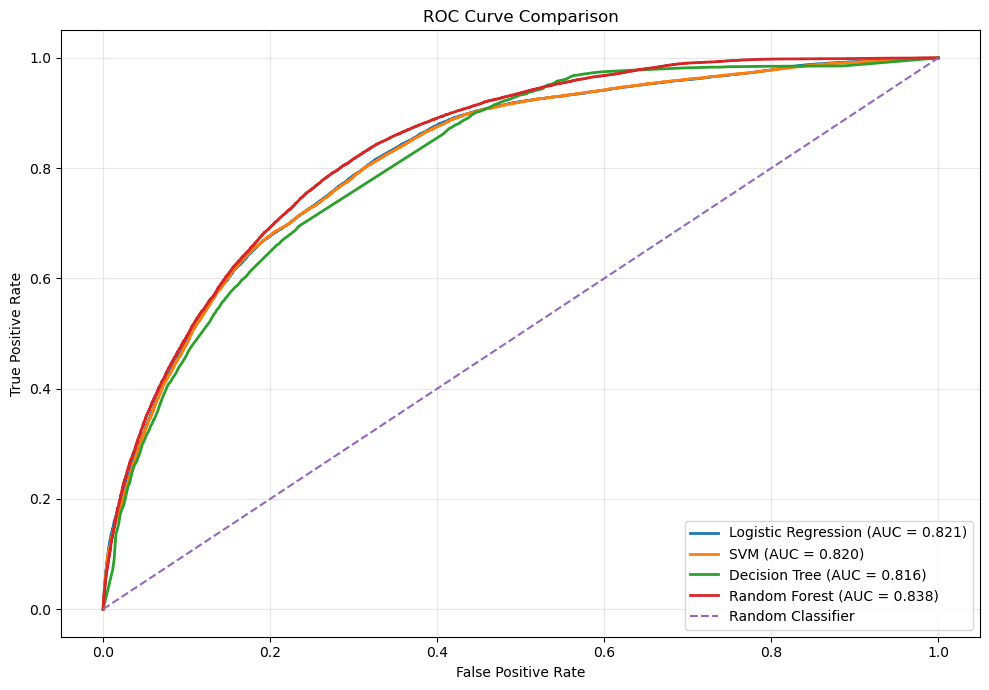

In [79]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 7))

for name in models.keys():

    y_score = scores[name]

    if y_score is None:
        continue

    fpr, tpr, _ = roc_curve(
        y_test,
        y_score
    )

    auc_value = roc_auc_score(
        y_test,
        y_score
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{name} "
            f"(AUC = {auc_value:.3f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve Comparison"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

# Classification report for every model

In [80]:
from sklearn.metrics import classification_report

for name in models.keys():

    print("=" * 70)

    print(
        f"CLASSIFICATION REPORT - {name}"
    )

    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                "Part 1",
                "Part 2"
            ],
            zero_division=0
        )
    )
    

CLASSIFICATION REPORT - Logistic Regression
              precision    recall  f1-score   support

      Part 1       0.81      0.75      0.78     35983
      Part 2       0.66      0.73      0.69     24017

    accuracy                           0.74     60000
   macro avg       0.73      0.74      0.74     60000
weighted avg       0.75      0.74      0.74     60000

CLASSIFICATION REPORT - SVM
              precision    recall  f1-score   support

      Part 1       0.81      0.74      0.77     35983
      Part 2       0.66      0.73      0.69     24017

    accuracy                           0.74     60000
   macro avg       0.73      0.74      0.73     60000
weighted avg       0.75      0.74      0.74     60000

CLASSIFICATION REPORT - Decision Tree
              precision    recall  f1-score   support

      Part 1       0.79      0.77      0.78     35983
      Part 2       0.67      0.69      0.68     24017

    accuracy                           0.74     60000
   macro avg      

# 23. Five-fold Cross Validation

In [82]:
CV_SAMPLE_SIZE = 50000

if len(model_df) > CV_SAMPLE_SIZE:

    cv_df, _ = train_test_split(
        model_df,
        train_size=CV_SAMPLE_SIZE,
        stratify=model_df[target],
        random_state=42
    )

else:

    cv_df = model_df.copy()

X_cv = cv_df[features]

y_cv = cv_df[target]

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    print(
        "Cross-validation:",
        name
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )
        ]
    )

    cv_scores = cross_val_score(
        pipeline,
        X_cv,
        y_cv,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean F1": cv_scores.mean(),
        "Std F1": cv_scores.std()
    })
    
cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df

Cross-validation: Logistic Regression
Cross-validation: SVM
Cross-validation: Decision Tree
Cross-validation: Random Forest


,Model,Mean F1,Std F1
0,Logistic Regression,0.696467,0.003169
1,SVM,0.696038,0.003145
2,Decision Tree,0.669006,0.008535
3,Random Forest,0.714405,0.004041


# Select the best model

In [84]:
best_model_name = (
    results_df
    .sort_values(
        "F1 Score",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "Best Model:",
    best_model_name
)
best_model = trained_models[
    best_model_name
]

Best Model: Random Forest


# Save the best model

In [85]:
import joblib

joblib.dump(
    best_model,
    "best_crime_classification_model.pkl"
)

print(
    "Best model saved successfully."
)

Best model saved successfully.


# save all four models too

In [86]:
for name, model in trained_models.items():

    filename = (
        name.lower()
        .replace(" ", "_")
        + ".pkl"
    )

    joblib.dump(
        model,
        filename
    )

    print(
        "Saved:",
        filename
    )

Saved: logistic_regression.pkl
Saved: svm.pkl
Saved: decision_tree.pkl
Saved: random_forest.pkl


# MODULE 2 — GEOGRAPHIC CRIME HOTSPOT ANALYSIS

# PART 46 — Geographic Dataset

In [87]:
geo_df = df[
    [
        "LAT",
        "LON",
        "AREA",
        "AREA NAME",
        "Crm Cd Desc",
        "Year",
        "Month",
        "Hour",
        "TimeOfDay",
        "Part 1-2"
    ]
].copy()

geo_df = geo_df.dropna(
    subset=[
        "LAT",
        "LON"
    ]
)

# Check Geographic Range

In [88]:
print(
    geo_df[
        ["LAT", "LON"]
    ].describe()
)

geo_df = geo_df[
    (geo_df["LAT"] != 0) &
    (geo_df["LON"] != 0)
]

                LAT           LON
count  1.005198e+06  1.005198e+06
mean   3.399820e+01 -1.180909e+02
std    1.610549e+00  5.581812e+00
min    0.000000e+00 -1.186676e+02
25%    3.401470e+01 -1.184305e+02
50%    3.405890e+01 -1.183225e+02
75%    3.416490e+01 -1.182739e+02
max    3.433430e+01  0.000000e+00


# Crime Density Map

In [90]:
map_sample = geo_df.sample(
    min(30000, len(geo_df)),
    random_state=42
)
crime_map = folium.Map(
    location=[
        map_sample["LAT"].mean(),
        map_sample["LON"].mean()
    ],
    zoom_start=10
)

# Heatmap

In [92]:
heat_data = map_sample[
    ["LAT", "LON"]
].values.tolist()

HeatMap(
    heat_data,
    radius=10,
    blur=15,
    min_opacity=0.3
).add_to(crime_map)

crime_map

# PART 50 — Interactive Crime Map by Area

In [93]:
area_geo = (
    geo_df
    .groupby("AREA NAME")
    .agg(
        Crime_Count=("AREA NAME", "size"),
        Latitude=("LAT", "mean"),
        Longitude=("LON", "mean")
    )
    .reset_index()
)

area_geo = area_geo.sort_values(
    "Crime_Count",
    ascending=False
)

area_geo.head(20)

,AREA NAME,Crime_Count,Latitude,Longitude
1,Central,69480,34.047659,-118.250586
0,77th Street,61630,33.977692,-118.297310
12,Pacific,59347,33.983535,-118.423498
15,Southwest,57446,34.020254,-118.316198
6,Hollywood,52108,34.099366,-118.329648
8,N Hollywood,51015,34.171628,-118.384630
11,Olympic,49941,34.060169,-118.300403
14,Southeast,49800,33.938888,-118.267151
9,Newton,49083,34.009579,-118.260593
20,Wilshire,48109,34.061854,-118.352082


# PART 52 — Crime Type Geographic Analysis

In [ ]:
crime_types = (
    geo_df["Crm Cd Desc"]
    .value_counts()
    .head(10)
    .index
)

crime_types

# MODULE 3 — HISTORICAL CRIME RISK PREDICTION

In [ ]:
We should NOT claim:

"The model predicts that a crime will definitely happen."

Instead:

"The system estimates historical crime risk based on previously observed crime frequency for a given area and time combination."

# PART 53 — Create Area-Time Groups

In [94]:
risk_base = df[
    [
        "AREA",
        "AREA NAME",
        "Hour",
        "DayOfWeek",
        "Month",
        "Year"
    ]
].copy()

risk_base = risk_base.dropna(
    subset=[
        "AREA",
        "Hour",
        "DayOfWeek"
    ]
)

# PART 54 — Calculate Historical Crime Frequency

In [95]:
risk_frequency = (
    risk_base
    .groupby(
        [
            "AREA",
            "AREA NAME",
            "Hour",
            "DayOfWeek"
        ]
    )
    .size()
    .reset_index(
        name="Crime_Count"
    )
)

risk_frequency.head()

,AREA,AREA NAME,Hour,DayOfWeek,Crime_Count
0,1,Central,0.0,0,360
1,1,Central,0.0,1,279
2,1,Central,0.0,2,318
3,1,Central,0.0,3,340
4,1,Central,0.0,4,341


# PART 55 — Create Risk Categories

In [96]:
q1 = risk_frequency[
    "Crime_Count"
].quantile(0.33)

q2 = risk_frequency[
    "Crime_Count"
].quantile(0.66)

print("Low threshold:", q1)
print("High threshold:", q2)

def assign_risk(count):

    if count <= q1:
        return "LOW"

    elif count <= q2:
        return "MEDIUM"

    else:
        return "HIGH"
    
risk_frequency["Risk"] = (
    risk_frequency["Crime_Count"]
    .apply(assign_risk)
)

risk_frequency["Risk"].value_counts()

Low threshold: 227.0
High threshold: 335.82000000000016


HIGH      1200
LOW       1167
MEDIUM    1161
Name: Risk, dtype: int64

# PART 56 — Risk Distribution

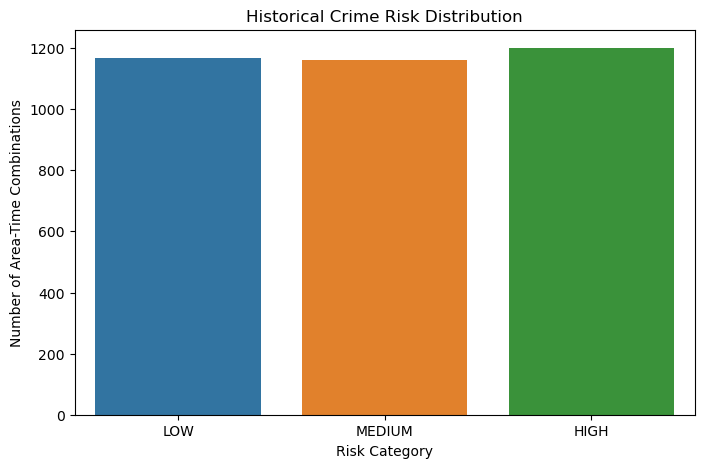

In [97]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_frequency,
    x="Risk",
    order=[
        "LOW",
        "MEDIUM",
        "HIGH"
    ]
)

plt.title(
    "Historical Crime Risk Distribution"
)

plt.xlabel("Risk Category")
plt.ylabel("Number of Area-Time Combinations")

plt.show()

# PART 57 — Risk by Area

In [98]:
risk_area = pd.crosstab(
    risk_frequency["AREA NAME"],
    risk_frequency["Risk"]
)
risk_area["Total"] = (
    risk_area.sum(axis=1)
)

risk_area = risk_area.sort_values(
    "Total",
    ascending=False
)

risk_area.head(20)

Risk,HIGH,LOW,MEDIUM,Total
AREA NAME,,,,
77th Street,110,27,31,168
Olympic,69,44,55,168
West Valley,30,59,79,168
West LA,56,57,55,168
Van Nuys,32,67,69,168
Topanga,38,76,54,168
Southwest,103,41,24,168
Southeast,66,41,61,168
Rampart,53,46,69,168


# PART 58 — Risk Prediction Model

In [104]:
risk_features = [
    "AREA",
    "AREA NAME",
    "Hour",
    "DayOfWeek"
]

risk_target = "Risk"

X_risk = risk_frequency[
    risk_features
]

y_risk = risk_frequency[
    risk_target
]

# PART 59 — Risk Train/Test Split

In [100]:
X_risk_train, X_risk_test, y_risk_train, y_risk_test = train_test_split(
    X_risk,
    y_risk,
    test_size=0.20,
    stratify=y_risk,
    random_state=42
)

# PART 60 — Risk Preprocessor

In [105]:
risk_numeric = [
    "AREA",
    "Hour",
    "DayOfWeek"
]

risk_categorical = [
    "AREA NAME"
]

risk_numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

risk_categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)
risk_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            risk_numeric_transformer,
            risk_numeric
        ),
        (
            "cat",
            risk_categorical_transformer,
            risk_categorical
        )
    ]
)

# PART 61 — Risk Model

In [106]:
risk_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
risk_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            risk_preprocessor
        ),
        (
            "model",
            risk_model
        )
    ]
)
risk_pipeline.fit(
    X_risk_train,
    y_risk_train
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['AREA', 'Hour',
                                                   'DayOfWeek']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['AREA NAME'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=15,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

# PART 62 — Evaluate Risk Model

In [107]:
risk_pred = risk_pipeline.predict(
    X_risk_test
)
print(
    classification_report(
        y_risk_test,
        risk_pred,
        zero_division=0
    )
)
risk_accuracy = accuracy_score(
    y_risk_test,
    risk_pred
)

print(
    "Risk Model Accuracy:",
    round(risk_accuracy, 4)
)

              precision    recall  f1-score   support

        HIGH       0.85      0.90      0.87       240
         LOW       0.91      0.90      0.91       234
      MEDIUM       0.79      0.75      0.77       232

    accuracy                           0.85       706
   macro avg       0.85      0.85      0.85       706
weighted avg       0.85      0.85      0.85       706

Risk Model Accuracy: 0.8499


# PART 64 — Save Risk Model

In [108]:
joblib.dump(
    risk_pipeline,
    "crime_risk_model.pkl"
)

['crime_risk_model.pkl']

# PART 65 — Test Risk Prediction

In [109]:
sample_risk = pd.DataFrame({
    "AREA": [1],
    "AREA NAME": ["Central"],
    "Hour": [23],
    "DayOfWeek": [5]
})

In [110]:
predicted_risk = risk_pipeline.predict(
    sample_risk
)

print(
    "Predicted Historical Risk:",
    predicted_risk[0]
)

Predicted Historical Risk: HIGH


In [111]:
risk_probability = (
    risk_pipeline
    .predict_proba(
        sample_risk
    )[0]
)

risk_classes = (
    risk_pipeline
    .named_steps["model"]
    .classes_
)

risk_result = pd.DataFrame({
    "Risk": risk_classes,
    "Probability": risk_probability
})

risk_result

,Risk,Probability
0,HIGH,0.987437
1,LOW,0.002083
2,MEDIUM,0.010480
